In [3]:
import h5py
import pandas as pd

model_path = "mofa_model_late_stage.hdf5"

with h5py.File(model_path, "r") as f:
    # Stored as factors × samples, so transpose to samples × factors
    Z = f["expectations"]["Z"]["group1"][()].T

    sample_names = [
        value.decode() if isinstance(value, bytes) else str(value)
        for value in f["samples"]["group1"][()]
    ]

df_factors = pd.DataFrame(
    Z,
    index=sample_names,
    columns=[f"Factor{i+1}" for i in range(Z.shape[1])]
)

print("MOFA factor matrix:", df_factors.shape)
print(df_factors.head())

MOFA factor matrix: (181, 10)
        Factor1   Factor2   Factor3   Factor4   Factor5   Factor6   Factor7  \
10023 -1.314417 -0.673131  1.374701  1.976976 -0.678562 -1.201905  0.274013   
10025  0.783891  0.098252  1.286066  1.207256 -0.842411 -1.340428  0.482659   
10029  1.719353 -0.633145 -0.084984  0.169663  0.470284  0.487512  0.035125   
10031 -0.732379 -0.847694  1.106549 -0.068854 -1.640253 -0.955076  0.499989   
10036 -1.205366 -0.449153  0.078196  1.597399  0.276566 -0.161771 -0.249917   

        Factor8   Factor9  Factor10  
10023  0.005799  0.006213 -0.938310  
10025 -0.232333  0.884652 -0.211149  
10029 -0.921056 -0.437380 -0.540923  
10031 -0.279597  1.480689  0.775345  
10036 -0.151175 -0.448226 -1.313583  


In [4]:
metadata = pd.read_csv("data/metadata.tsv", sep="\t")
metadata["Sample"] = metadata["Sample"].astype(str)

metadata = (
    metadata[
        metadata["Study.Group"].isin(["Healthy", "Stage_III_IV"])
    ]
    .copy()
    .set_index("Sample")
)

metadata["Binary.Group"] = (
    metadata["Study.Group"] == "Stage_III_IV"
).astype(int)

print(metadata.shape)

(181, 15)


In [5]:
common_samples = df_factors.index.intersection(metadata.index)

X_mofa = df_factors.loc[common_samples].copy()
y_mofa_label = metadata.loc[common_samples, "Binary.Group"].copy()

print("X_mofa:", X_mofa.shape)
print("\nClass counts:")
print(y_mofa_label.value_counts())

print(
    "\nSame sample order:",
    X_mofa.index.equals(y_mofa_label.index)
)

X_mofa: (181, 10)

Class counts:
Binary.Group
0    127
1     54
Name: count, dtype: int64

Same sample order: True


Exploratory MOFA-XGBoost ROC-AUC: 0.701


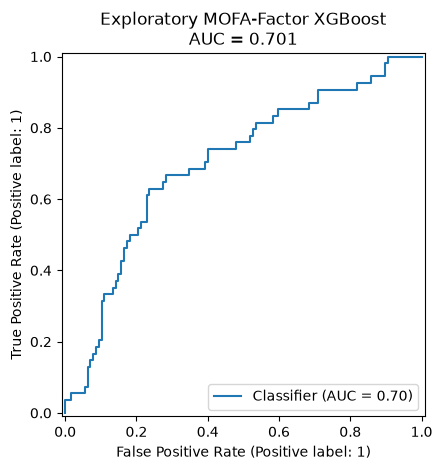

In [6]:
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import roc_auc_score, RocCurveDisplay
from xgboost import XGBClassifier
import matplotlib.pyplot as plt

xgb_mofa_pipe = Pipeline([
    (
        "model",
        XGBClassifier(
            n_estimators=300,
            max_depth=3,
            learning_rate=0.05,
            subsample=0.8,
            colsample_bytree=0.8,
            objective="binary:logistic",
            eval_metric="logloss",
            tree_method="hist",
            random_state=42,
            n_jobs=2
        )
    )
])

cv_mofa = StratifiedKFold(
    n_splits=10,
    shuffle=True,
    random_state=42
)

y_mofa_proba = cross_val_predict(
    xgb_mofa_pipe,
    X_mofa,
    y_mofa_label,
    cv=cv_mofa,
    method="predict_proba",
    n_jobs=1
)[:, 1]

auc_mofa = roc_auc_score(
    y_mofa_label,
    y_mofa_proba
)

print("Exploratory MOFA-XGBoost ROC-AUC:", round(auc_mofa, 3))

RocCurveDisplay.from_predictions(
    y_mofa_label,
    y_mofa_proba
)

plt.title(
    f"Exploratory MOFA-Factor XGBoost\nAUC = {auc_mofa:.3f}"
)
plt.tight_layout()
plt.show()

In [7]:
xgb_mofa_pipe.fit(
    X_mofa,
    y_mofa_label
)

mofa_model = xgb_mofa_pipe.named_steps["model"]

print("MOFA-factor XGBoost fitted for interpretation.")

MOFA-factor XGBoost fitted for interpretation.


In [8]:
import shap

explainer = shap.TreeExplainer(mofa_model)

shap_values = explainer.shap_values(X_mofa)

print(type(shap_values))

/data/scratch/sohaj01/crc_project/crc_env/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


<class 'numpy.ndarray'>


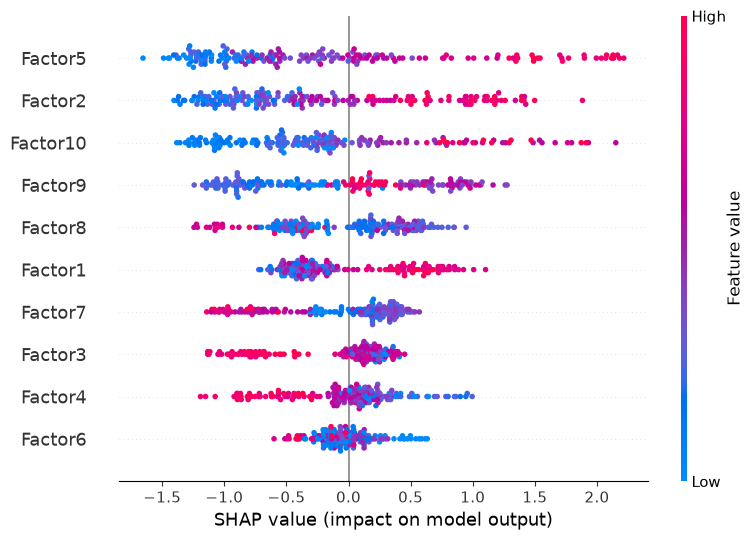

In [9]:
shap.summary_plot(
    shap_values,
    X_mofa
)

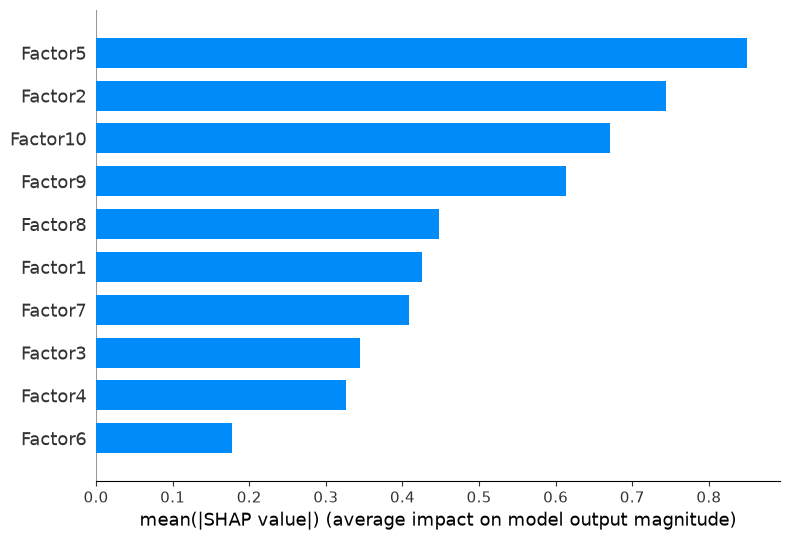

In [10]:
shap.summary_plot(
    shap_values,
    X_mofa,
    plot_type="bar"
)

In [11]:
# Factor 5 (remember Python starts at 0)
factor5 = genera_weights.iloc[4]

print(factor5.head())

NameError: name 'genera_weights' is not defined